In [25]:
import torch
from utils import load_fwd

s, d, _, _ = load_fwd('single-fp16.pt', 'fp16')

FileNotFoundError: [Errno 2] No such file or directory: 'single-fp16.pt'

In [ ]:
single = s['batch_0.layer_1.attn'].view(-1).to(torch.float32); distri = d['batch_0.layer_1.attn'].view(-1).to(torch.float32)

In [ ]:
mask1 = torch.abs(single) > 6e-5
mask2 = torch.abs(distri) > 6e-5
mask = mask1 & mask2

In [ ]:
ss = single[mask]; dd = distri[mask]

In [ ]:
rel = torch.abs(ss - dd) / torch.abs(ss)

In [ ]:
a = rel.sort()[0]

In [ ]:
a[int(len(a)*0.90)]

tensor(0.0005)

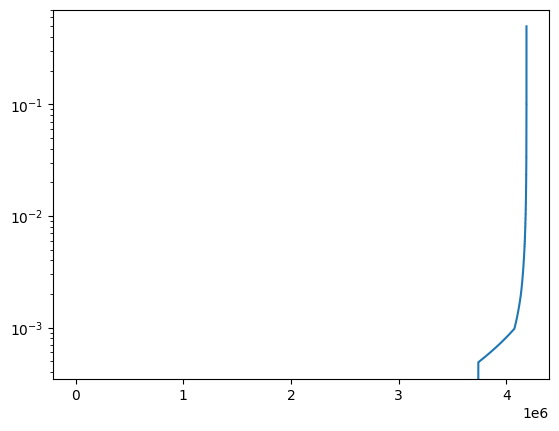

In [ ]:
import matplotlib.pyplot as plt
plt.plot(range(len(a)), a.numpy())
plt.yscale('log')

In [ ]:
a[3739076], len(a)

(tensor(0.0005), 4187279)

In [ ]:
_, buggy, _, _ = load_fwd('single-fp16.pt', 'buggy-fp16')

In [ ]:
bb = buggy['batch_0.layer_1.attn'].view(-1).to(torch.float32)[mask]

In [ ]:
brel = torch.abs(ss - bb) / torch.abs(ss)

In [ ]:
b = brel.sort()[0]

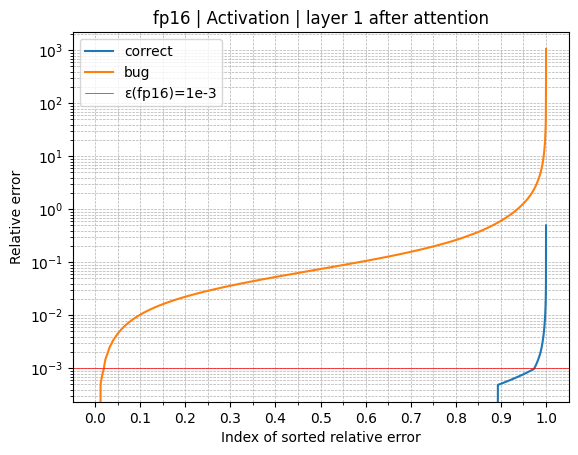

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.plot(np.arange(len(a))/len(a), a.numpy())
plt.plot(np.arange(len(b))/len(b), b.numpy())
plt.axhline(y=1e-3, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.yscale('log')
plt.legend(['correct', 'bug', 'ε(fp16)=1e-3'])
plt.xlabel('Index of sorted relative error')
plt.ylabel('Relative error')
plt.title('fp16 | Activation | layer 1 after attention')
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(0.1))  # 每 1 个单位一个主刻度
plt.gca().xaxis.set_minor_locator(ticker.MultipleLocator(0.05))  # 每 0.2 个单位一个次刻度
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

In [ ]:
(torch.searchsorted(a, 1e-3) / a.size(0)).item()*100, (torch.searchsorted(b, 1e-3) / b.size(0)).item()*100

(97.37860560417175, 1.931421272456646)

---

In [ ]:
import torch
from utils import *

single, distri, _, _ = load_fwd('bf16.pt', 'bf16')
_, buggy, _, _ = load_fwd('bf16.pt', 'bf16-bug')

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 12

In [ ]:
corr_rel_err = []
bug_rel_err = []
for i in range(1,2): # 32):
    s = single[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    d = distri[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    b = buggy[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    corr_rel_err.append(get_rel_err(s, d))
    bug_rel_err.append(get_rel_err(s, b))
legend = ['Correct', 'Buggy']

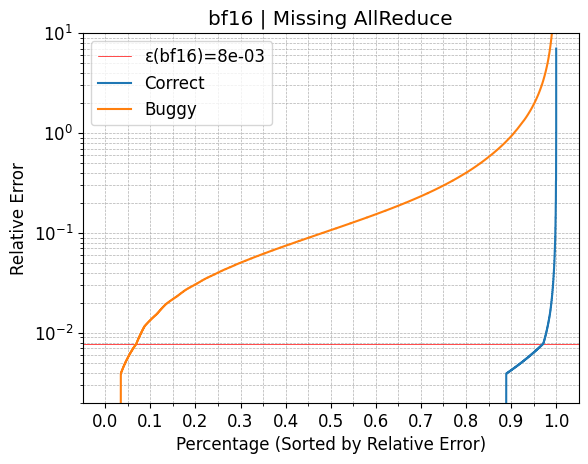

In [ ]:
plot("bf16", corr_rel_err + bug_rel_err, legend, 'Wrong Word Embedding', ylim=[2e-3,10])

In [ ]:
epsilon = epsilons["bf16"]
for i in range(32):
    quantile_corr = torch.searchsorted(corr_rel_err[i], epsilon) / corr_rel_err[i].size(0)
    quantile_corr = quantile_corr.item() * 100
    quantile_bug = torch.searchsorted(bug_rel_err[i], epsilon) / bug_rel_err[i].size(0)
    quantile_bug = quantile_bug.item() * 100
    print(f"Batch {i} correct: {quantile_corr:.2f}%, bug: {quantile_bug:.2f}%")

Batch 0 correct: 97.26%, bug: 8.16%
Batch 1 correct: 97.11%, bug: 6.87%
Batch 2 correct: 97.09%, bug: 7.83%
Batch 3 correct: 96.92%, bug: 6.00%
Batch 4 correct: 97.08%, bug: 7.30%
Batch 5 correct: 97.19%, bug: 9.78%
Batch 6 correct: 97.23%, bug: 7.24%
Batch 7 correct: 97.17%, bug: 4.80%
Batch 8 correct: 97.09%, bug: 4.20%
Batch 9 correct: 96.97%, bug: 7.90%
Batch 10 correct: 97.05%, bug: 5.76%
Batch 11 correct: 97.15%, bug: 5.23%
Batch 12 correct: 97.15%, bug: 8.48%
Batch 13 correct: 97.17%, bug: 7.53%
Batch 14 correct: 97.20%, bug: 4.70%
Batch 15 correct: 97.11%, bug: 7.31%
Batch 16 correct: 97.23%, bug: 5.91%
Batch 17 correct: 97.11%, bug: 4.58%
Batch 18 correct: 97.03%, bug: 6.67%
Batch 19 correct: 97.29%, bug: 5.04%
Batch 20 correct: 97.18%, bug: 5.34%
Batch 21 correct: 97.14%, bug: 6.01%
Batch 22 correct: 97.06%, bug: 6.78%
Batch 23 correct: 97.02%, bug: 4.33%
Batch 24 correct: 97.22%, bug: 4.48%
Batch 25 correct: 97.16%, bug: 4.55%
Batch 26 correct: 97.19%, bug: 5.40%
Batch 27 co

In [1]:
import torch
from utils import *

single_fp16, distri_fp16, _, _ = load_fwd('fp16.pt', 'fp16')
_, buggy_fp16, _, _ = load_fwd('fp16.pt', 'fp16-bug')

In [2]:
corr_rel_err_fp16 = []
bug_rel_err_fp16 = []
for i in range(1,2):
    s = single_fp16[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    d = distri_fp16[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    b = buggy_fp16[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    corr_rel_err_fp16.append(get_rel_err(s, d))
    bug_rel_err_fp16.append(get_rel_err(s, b))
legend = ['Correct', 'Buggy']

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']

[6.4, 4.8]

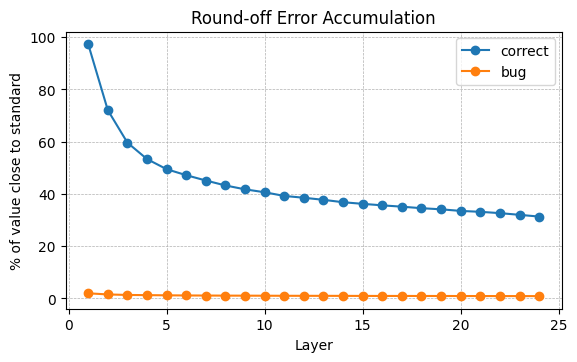

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [6.4, 3.6]
epsilon = epsilons["fp16"]
quantiles_corr = []
quantiles_bugg = []
for i in range(1):
    quantile1 = []
    quantile2 = []
    for l in range(1, 25):
        s = single_fp16[f'batch_{i}.layer_{l}.attn'].view(-1).to(torch.float32)
        d = distri_fp16[f'batch_{i}.layer_{l}.attn'].view(-1).to(torch.float32)
        b = buggy_fp16[f'batch_{i}.layer_{l}.attn'].view(-1).to(torch.float32)
        rel_err = get_rel_err(s, d)
        bug_err = get_rel_err(s, b)
        quan1 = (torch.searchsorted(rel_err, epsilon) / rel_err.size(0)).item() * 100
        quan2 = (torch.searchsorted(bug_err, epsilon) / bug_err.size(0)).item() * 100
        quantile1.append(quan1)
        quantile2.append(quan2)
    quantiles_corr.append(quantile1)
    quantiles_bugg.append(quantile2)

import matplotlib.pyplot as plt
for i in range(1):
    plt.plot(range(1, 25), quantiles_corr[i], '-o')
    plt.plot(range(1, 25), quantiles_bugg[i], '-o')
plt.legend(['correct', 'bug'])
plt.xlabel('Layer')
plt.ylabel('% of value close to standard')
plt.title('Round-off Error Accumulation')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

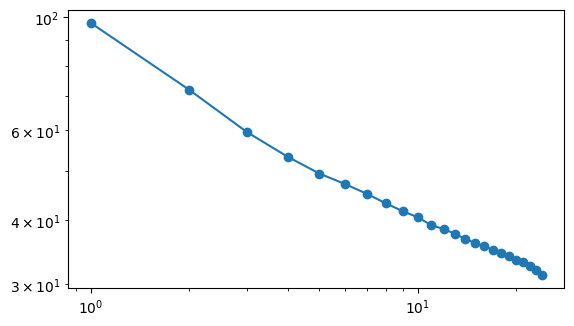

In [7]:
# import matplotlib.pyplot as plt
# plt.rcParams['figure.figsize'] = [6.4, 3.6]
# epsilon = epsilons["fp16"]
# quantiles_corr = []
# quantiles_bugg = []
# for i in range(1):
#     quantile1 = []
#     quantile2 = []
#     for l in range(1, 25):
#         s = single_fp16[f'batch_{i}.layer_{l}.attn'].view(-1).to(torch.float32)
#         d = distri_fp16[f'batch_{i}.layer_{l}.attn'].view(-1).to(torch.float32)
#         b = buggy_fp16[f'batch_{i}.layer_{l}.attn'].view(-1).to(torch.float32)
#         rel_err = get_rel_err(s, d)
#         bug_err = get_rel_err(s, b)
#         quan1 = (torch.searchsorted(rel_err, epsilon) / rel_err.size(0)).item() * 100
#         quan2 = (torch.searchsorted(bug_err, epsilon) / bug_err.size(0)).item() * 100
#         quantile1.append(quan1)
#         quantile2.append(quan2)
#     quantiles_corr.append(quantile1)
#     quantiles_bugg.append(quantile2)

# plt.plot(np.log(np.arange(1, 25)), np.log(quantiles_corr[0]), '-o')
plt.plot(np.arange(1, 25), quantiles_corr[0], '-o')

In [10]:
for l, p in enumerate(quantiles_corr[0]):
    if l >= 4:
        print(p*(l**(0.2837)))

73.21731567133214
74.37452310087988
74.9404563333475
74.99875860363154
75.21328681604359
75.68866023683313
75.28500528763738
75.97310723466093
76.26076044494543
76.12229507699787
76.42149878459121
76.69994977706695
76.98896982707831
77.03419024094042
77.31703163105325
77.10661244884541
77.42587693190373
77.31094248411455
76.77762293349409
76.12035683544704


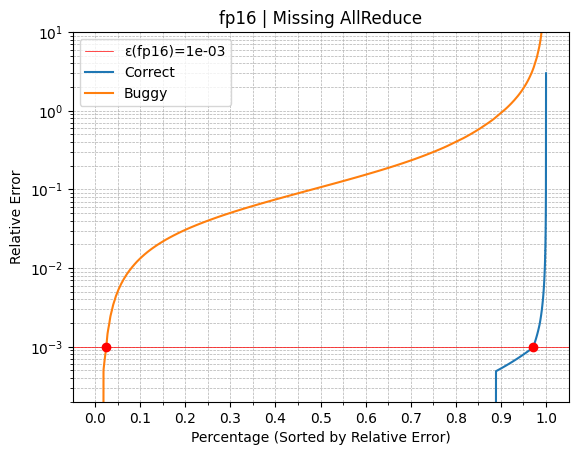

In [3]:
plot("fp16", corr_rel_err_fp16 + bug_rel_err_fp16, legend, 'Missing AllReduce', ylim=[2e-4, 10])
plt.plot(0.0248, 9.8e-4, 'ro')
plt.plot(0.9711, 9.8e-4, 'ro')

In [ ]:
epsilon = epsilons["fp16"]
for i in range(1):
    quantile_corr = torch.searchsorted(corr_rel_err_fp16[i], epsilon) / corr_rel_err_fp16[i].size(0)
    quantile_corr = quantile_corr.item() * 100
    quantile_bug = torch.searchsorted(bug_rel_err_fp16[i], epsilon) / bug_rel_err_fp16[i].size(0)
    quantile_bug = quantile_bug.item() * 100
    print(f"Batch {i} correct: {quantile_corr:.2f}%, bug: {quantile_bug:.2f}%")

Batch 0 correct: 97.11%, bug: 2.48%


---

In [ ]:
import torch
from utils import *

single, distri, _, _ = load_fwd('bf16-128.pt', 'bf16-128')
_, buggy, _, _ = load_fwd('bf16-128.pt', 'bf16-128-reduce')

In [ ]:
corr_rel_err = []
bug_rel_err = []
for i in range(32):
    s = single[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    d = distri[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    b = buggy[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    corr_rel_err.append(get_rel_err(s, d))
    bug_rel_err.append(get_rel_err(s, b))
# legend = ['correct_batch_0', 'correct_batch_1', 'buggy_batch_0', 'buggy_batch_1']

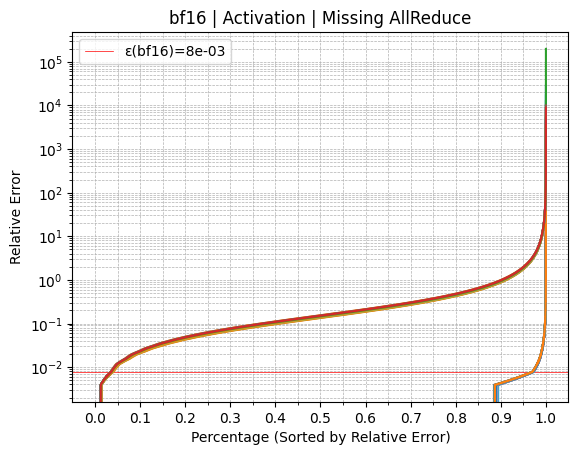

In [ ]:
plot("bf16", corr_rel_err + bug_rel_err, [], 'Activation | Missing AllReduce')

In [ ]:
epsilon = epsilons["bf16"]
for i in range(32):
    quantile_corr = torch.searchsorted(corr_rel_err[i], epsilon) / corr_rel_err[i].size(0)
    quantile_corr = quantile_corr.item() * 100
    quantile_bug = torch.searchsorted(bug_rel_err[i], epsilon) / bug_rel_err[i].size(0)
    quantile_bug = quantile_bug.item() * 100
    print(f"Batch {i} correct: {quantile_corr:.2f}%, bug: {quantile_bug:.2f}%")

Batch 0 correct: 97.26%, bug: 3.99%
Batch 1 correct: 97.11%, bug: 3.74%
Batch 2 correct: 97.09%, bug: 3.65%
Batch 3 correct: 96.92%, bug: 3.45%
Batch 4 correct: 97.08%, bug: 3.69%
Batch 5 correct: 97.19%, bug: 3.85%
Batch 6 correct: 97.23%, bug: 3.86%
Batch 7 correct: 97.17%, bug: 3.84%
Batch 8 correct: 97.09%, bug: 3.69%
Batch 9 correct: 96.97%, bug: 3.47%
Batch 10 correct: 97.05%, bug: 3.59%
Batch 11 correct: 97.15%, bug: 3.85%
Batch 12 correct: 97.15%, bug: 3.85%
Batch 13 correct: 97.17%, bug: 3.84%
Batch 14 correct: 97.20%, bug: 3.85%
Batch 15 correct: 97.11%, bug: 3.77%
Batch 16 correct: 97.23%, bug: 3.95%
Batch 17 correct: 97.11%, bug: 3.77%
Batch 18 correct: 97.03%, bug: 3.61%
Batch 19 correct: 97.29%, bug: 4.07%
Batch 20 correct: 97.18%, bug: 3.87%
Batch 21 correct: 97.14%, bug: 3.73%
Batch 22 correct: 97.06%, bug: 3.60%
Batch 23 correct: 97.02%, bug: 3.53%
Batch 24 correct: 97.22%, bug: 3.84%
Batch 25 correct: 97.16%, bug: 3.79%
Batch 26 correct: 97.19%, bug: 3.90%
Batch 27 co

In [ ]:
import torch
from utils import *

single, distri, _, _ = load_fwd('fp16-128.pt', 'fp16-128')
_, buggy, _, _ = load_fwd('fp16-128.pt', 'fp16-128-reduce')

In [ ]:
corr_rel_err = []
bug_rel_err = []
for i in range(32):
    s = single[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    d = distri[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    b = buggy[f'batch_{i}.layer_1.attn'].view(-1).to(torch.float32)
    corr_rel_err.append(get_rel_err(s, d))
    bug_rel_err.append(get_rel_err(s, b))
# legend = ['correct_batch_0', 'correct_batch_1', 'buggy_batch_0', 'buggy_batch_1']

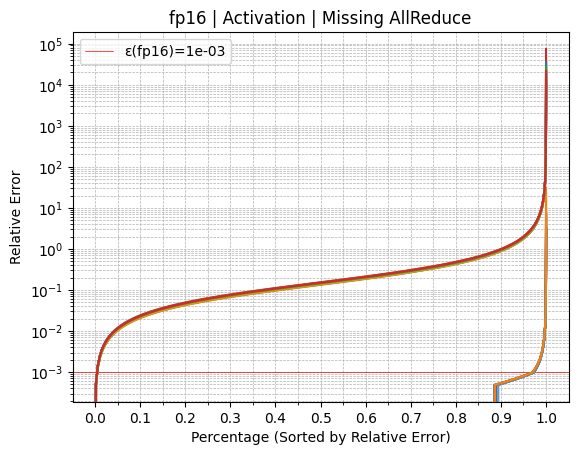

In [ ]:
plot("fp16", corr_rel_err + bug_rel_err, [], 'Activation | Missing AllReduce')

In [ ]:
epsilon = epsilons["fp16"]
for i in range(32):
    quantile_corr = torch.searchsorted(corr_rel_err[i], epsilon) / corr_rel_err[i].size(0)
    quantile_corr = quantile_corr.item() * 100
    quantile_bug = torch.searchsorted(bug_rel_err[i], epsilon) / bug_rel_err[i].size(0)
    quantile_bug = quantile_bug.item() * 100
    print(f"Batch {i} correct: {quantile_corr:.2f}%, bug: {quantile_bug:.2f}%")

Batch 0 correct: 97.27%, bug: 0.50%
Batch 1 correct: 97.11%, bug: 0.47%
Batch 2 correct: 97.11%, bug: 0.46%
Batch 3 correct: 96.93%, bug: 0.44%
Batch 4 correct: 97.09%, bug: 0.47%
Batch 5 correct: 97.20%, bug: 0.48%
Batch 6 correct: 97.26%, bug: 0.49%
Batch 7 correct: 97.20%, bug: 0.49%
Batch 8 correct: 97.14%, bug: 0.47%
Batch 9 correct: 96.99%, bug: 0.44%
Batch 10 correct: 97.07%, bug: 0.45%
Batch 11 correct: 97.17%, bug: 0.48%
Batch 12 correct: 97.17%, bug: 0.49%
Batch 13 correct: 97.20%, bug: 0.48%
Batch 14 correct: 97.22%, bug: 0.48%
Batch 15 correct: 97.13%, bug: 0.47%
Batch 16 correct: 97.25%, bug: 0.49%
Batch 17 correct: 97.12%, bug: 0.47%
Batch 18 correct: 97.05%, bug: 0.46%
Batch 19 correct: 97.32%, bug: 0.51%
Batch 20 correct: 97.21%, bug: 0.49%
Batch 21 correct: 97.17%, bug: 0.48%
Batch 22 correct: 97.08%, bug: 0.45%
Batch 23 correct: 97.02%, bug: 0.45%
Batch 24 correct: 97.24%, bug: 0.48%
Batch 25 correct: 97.19%, bug: 0.48%
Batch 26 correct: 97.22%, bug: 0.49%
Batch 27 co